# Step 7. The frozen reader on the 50 Mendeley exams

**The question.** Every choice of the reader is now made (steps 4 and 6), on public data only. How well does
it read real exams it has never seen? The Mendeley dataset "A Dataset of Digitized Student Examination Papers"
(CC BY 4.0, <https://data.mendeley.com/datasets/sf3kvjwknt/1>) has 50 scanned handwritten exams, the answer key,
and the teacher's marks: the only public data with whole exam pages, numbered answers and a key.

This is the first time since step 2 that anything looks at these exams, and nothing here changes the reader.
The structure of the data is described first (no handwriting and no names are shown); then all five ways of
reading are compared, once.

    Part 1  The data      the key, the teacher's sheet and the scans: structure, cleaning, EDA
    Part 2  Evaluation    rules, detectors, ocr, and the page reader with 2B (the product) and 4B
    Part 3  Where it fails  per question and per exam, and whether its confidence flags its mistakes

Run with `uv run python -m vision.step7_evaluate` after downloading the data (vision/README.md). Reads are cached
per exam and per reader version in `~/.cache/daiist-vision/reader_cache/`, so a second run reads nothing again.

In [1]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vision" / "reader.py").is_file())
sys.path.insert(0, str(ROOT))

import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402

from vision import datasets, eda, reader  # noqa: E402

pd.set_option("display.width", 140)
OUT = datasets.ARTIFACTS / "step7_evaluation"
MENDELEY = datasets.WORK / "mendeley"
CACHE = datasets.WORK / "reader_cache"
# The five ways of reading. The LoRA reader of step 6 is not evaluated here: it was rejected on the development
# set, and evaluating it on Mendeley could only tempt a choice the rules of this project forbid.
PAGE_MODELS = {"page": reader.BASE_PAGE_READER, "page-4b": "Qwen/Qwen3-VL-4B-Instruct"}
MODES = ["rules", "detectors", "ocr", "page", "page-4b"]

## Part 1. The data

Three files are used, and the rest of the download is left where it is:

- `answerkey.txt`: each question's number, type (MCQ or written) and correct answer.
- `Teacher_manual_marks_Anonymized.csv`: per student, what the teacher recorded for each question: the letter
  written for a multiple-choice question, the mark for a written one.
- `Student_<n>.pdf`: the raw scans, without the teacher's marks drawn on them.

Left out on purpose: `Corrected_Pdf/` shows the teacher's ticks on the pages (it would show the reader the
grading), `Student_MCQ.csv` and `file.txt` hold names and student ID numbers, and the marks file's
`Student_Name` column is not anonymised despite the file's name, so it is dropped on loading if present.

In [2]:
key_path, marks_path = MENDELEY / "answerkey.txt", MENDELEY / "Teacher_manual_marks_Anonymized.csv"
pdfs = sorted((MENDELEY / "pdfs").glob("Student_*.pdf"), key=lambda p: int(p.stem.split("_")[1]))
if not key_path.is_file() or not marks_path.is_file() or not pdfs:
    raise SystemExit(f"Download the dataset and put answerkey.txt and Teacher_manual_marks_Anonymized.csv in "
                     f"{MENDELEY}, and the raw Student_<n>.pdf files in {MENDELEY / 'pdfs'} (vision/README.md).")
key = pd.read_csv(key_path)
key["Question_Number"] = key["Question_Number"].astype(str)
# As text: the sheet mixes letters, marks and codes in the same columns, and pandas would otherwise turn some of
# them into numbers or booleans. Empty cells stay missing (NaN) and count as not answered.
marks = pd.read_csv(marks_path, dtype=str).set_index("Student_ID")
marks = marks.drop(columns=[c for c in marks.columns if "name" in c.lower()])  # personal data, never used
# NC is "not corrected" (blank or skipped) in the dataset's README; NM and "-" appear the same way.
NOT_MARKED = {"NC", "NM", "-", ""}

eda.show(key.groupby("Type").agg(questions=("Question_Number", "size"),
                                 numbers=("Question_Number", lambda s: f"{s.astype(int).min()}-{s.astype(int).max()}")),
         "The answer key:")
eda.show(key[key["Type"] == "MCQ"]["Correct_Answer"].value_counts().sort_index(), "Correct letters in the key:")


The answer key:


,questions,numbers
Type,,
MCQ,20,1-20
Short_Answer,15,21-35



Correct letters in the key:


Correct_Answer
A    4
B    9
C    7
Name: count, dtype: int64


Answers in the teacher's sheet:


,cells,answered,share answered
type,,,
MCQ,1000,989,0.989
Short_Answer,750,565,0.753



Codes for 'not answered':


cell
(empty)    189
-            4
NC           2
NM           1
Name: count, dtype: int64


Letters the students wrote (multiple choice):


cell
C       351
B       314
A       196
D       126
TRUE      1
2         1
Name: count, dtype: int64

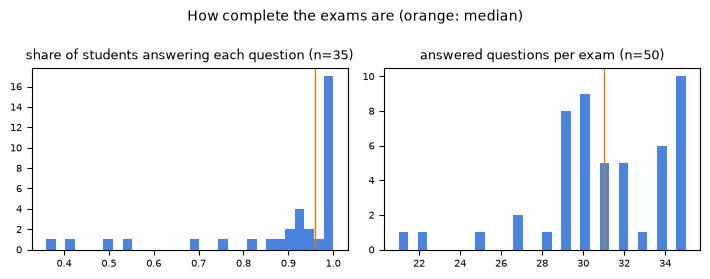

figure: eda_answers.png


In [3]:
cells = marks[key["Question_Number"]].fillna("").stack().rename("cell").reset_index()
cells.columns = ["exam", "question", "cell"]
cells["type"] = cells["question"].map(key.set_index("Question_Number")["Type"])
cells["answered"] = ~cells["cell"].str.strip().str.upper().isin(NOT_MARKED)
eda.show(cells.groupby("type")["answered"].agg(["size", "sum", "mean"]).rename(
    columns={"size": "cells", "sum": "answered", "mean": "share answered"}), "Answers in the teacher's sheet:")
eda.show(cells.loc[~cells["answered"], "cell"].replace("", "(empty)").value_counts(), "Codes for 'not answered':")
eda.show(cells.loc[cells["answered"] & (cells["type"] == "MCQ"), "cell"].str.upper().value_counts(),
         "Letters the students wrote (multiple choice):")
per_question = cells.groupby("question")["answered"].mean().reindex(key["Question_Number"])
eda.histograms({"share of students answering each question": per_question,
                "answered questions per exam": cells.groupby("exam")["answered"].sum()},
               "", OUT / "eda_answers.png", "How complete the exams are (orange: median)")

In [4]:
pages = []
for pdf in pdfs:
    for n, page in enumerate(reader.load_pages(pdf), start=1):
        pages.append({"exam": pdf.stem, "page": n, "height": page.shape[0], "width": page.shape[1],
                      "ink": reader.ink(page), "blank": reader.ink(page) < reader.BLANK_INK})
pages = pd.DataFrame(pages)
eda.show(pd.DataFrame({c: eda.describe(pages.groupby("exam").size() if c == "pages per exam" else pages[c])
                       for c in ("pages per exam", "height", "ink")}), "The scans (pages rendered 2000 px wide):", digits=4)
print(f"pages under the blank-page threshold ({reader.BLANK_INK}), so never sent to the model: "
      f"{int(pages['blank'].sum())} of {len(pages)}")
pages.to_csv(OUT / "pages.csv", index=False)


The scans (pages rendered 2000 px wide):


,pages per exam,height,ink
count,50.0,200.0,200.0000
missing,0.0,0.0,0.0000
min,2.0,2829.0,0.0000
median,4.0,2829.0,0.0253
mean,4.0,2829.0,0.0242
max,6.0,2829.0,0.0695


pages under the blank-page threshold (0.001), so never sent to the model: 8 of 200


**What the data says.** 35 questions per exam, 20 multiple choice (1-20) and 15 written (21-35). Students
answered 99% of the multiple-choice questions but only 75% of the written ones, and a reader cannot find an answer
that is not there, so every rate below counts **answered questions only**. Two multiple-choice cells hold
something other than a letter ("TRUE", "2"); they count as answered, and no letter read can match them. Exams
have 2 to 6 pages (median 4); 8 of the 200 pages are empty and are never sent to the model.

## Part 2. Evaluation

What is checked, against the key and the teacher's sheet:

- **Questions found**: every answered question of the key that the reader found by its number.
- **Multiple choice**: the teacher's sheet has the letter each student wrote, so the letter read is checked
  answer by answer (`reader.choice_letter` takes a letter only when exactly one option letter stands alone).
- **Written answers**: there is no transcription, so only whether each answered question was found.
- **Numbers read that are not in the key**: misreads, or page furniture taken for a question.

In [5]:


def read_cached(pdf: Path, mode: str) -> dict:
    """mode is a reader mode, or 'page-4b' for the page mode with the 4B model. A cached read is used only if it
    was made by exactly this reader version (reader.versions), so a changed reader is never scored on old reads."""
    reader_mode = "page" if mode in PAGE_MODELS else mode
    if mode in PAGE_MODELS:
        reader.PAGE_READER = PAGE_MODELS[mode]
    cache = CACHE / mode / f"{pdf.stem}.json"
    if cache.is_file():
        saved = json.loads(cache.read_text())
        if saved.get("versions") == reader.versions(reader_mode):
            return saved
    result = reader.read_exam(pdf, reader_mode)
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_text(json.dumps(result))
    return result


def evaluate(mode: str) -> tuple[pd.DataFrame, list, list]:
    rows, extra, seconds = [], [], []
    for pdf in pdfs:
        result = read_cached(pdf, mode)
        seconds.append(result["stats"]["seconds"])
        found = reader.answers_by_number(result, expected=set(key["Question_Number"]))
        truth = marks.loc[pdf.stem]
        for _, q in key.iterrows():
            number, is_mcq = q["Question_Number"], q["Type"] == "MCQ"
            answer = found.get(number)
            teacher = truth.get(number)
            teacher = None if pd.isna(teacher) or str(teacher).strip().upper() in NOT_MARKED else str(teacher).strip()
            row = {"mode": mode, "exam": pdf.stem, "q": int(number), "type": "mcq" if is_mcq else "written",
                   "found": answer is not None, "ocr_conf": answer["ocr_conf"] if answer else np.nan,
                   "number_conf": answer["number_conf"] if answer else np.nan,
                   "duplicate": bool(answer and answer["duplicate"])}
            if is_mcq:
                wrote = teacher.upper() if teacher is not None else None
                read = reader.choice_letter(answer["text"], "ABCD") if answer else None
                row |= {"answered": wrote is not None, "wrote": wrote, "read": read, "letter_right": read == wrote}
            else:
                row |= {"answered": teacher is not None}  # the teacher gave a mark, so there is an answer
            rows.append(row)
        extra.append(sum(number not in set(key["Question_Number"]) for number in found))
    return pd.DataFrame(rows), seconds, extra


def summarise(rows: pd.DataFrame, seconds: list, extra: list) -> dict:
    mcq = rows[(rows["type"] == "mcq") & rows["answered"]]
    written = rows[(rows["type"] == "written") & rows["answered"]]
    letters_read = mcq["read"].notna()
    return {
        "exams": rows["exam"].nunique(),
        "questions_in_key_found": rows.loc[rows["answered"], "found"].mean(),
        "mcq_answers": len(mcq),
        "mcq_letter_read_rate": letters_read.mean(),
        "mcq_letter_accuracy_when_read": mcq.loc[letters_read, "letter_right"].mean(),
        "mcq_letter_accuracy_overall": mcq["letter_right"].mean(),
        "written_answers": len(written),
        "written_found_rate": written["found"].mean(),
        "numbers_not_in_key_per_exam": float(np.mean(extra)),
        "duplicates_per_exam": rows.groupby("exam")["duplicate"].sum().mean(),
        "seconds_per_exam_median": float(np.median(seconds)),
    }


all_rows, summary = [], {}
for mode in MODES:
    rows, seconds, extra = evaluate(mode)
    all_rows.append(rows)
    summary[mode] = summarise(rows, seconds, extra)
    print(f"{mode}: {len(pdfs)} exams read")
rows = pd.concat(all_rows, ignore_index=True)
summary = pd.DataFrame(summary)
eda.show(summary, "The frozen reader on all 50 Mendeley exams, five ways of reading:")
rows.to_csv(OUT / "reader_eval_questions.csv", index=False)
summary.rename_axis("metric").to_csv(OUT / "reader_eval_summary.csv")

rules: 50 exams read
detectors: 50 exams read
ocr: 50 exams read


page: 50 exams read


page-4b: 50 exams read

The frozen reader on all 50 Mendeley exams, five ways of reading:


,rules,detectors,ocr,page,page-4b
exams,50.000,50.000,50.000,50.000,50.000
questions_in_key_found,0.136,0.109,0.272,0.862,0.834
mcq_answers,989.000,989.000,989.000,989.000,989.000
mcq_letter_read_rate,0.061,0.009,0.142,0.823,0.771
mcq_letter_accuracy_when_read,0.750,0.556,0.836,0.989,0.986
mcq_letter_accuracy_overall,0.046,0.005,0.118,0.814,0.760
written_answers,565.000,565.000,565.000,565.000,565.000
written_found_rate,0.037,0.202,0.248,0.830,0.858
numbers_not_in_key_per_exam,1.260,0.400,1.400,4.480,14.280
duplicates_per_exam,0.900,0.640,0.600,2.060,2.100


In [6]:
# Every Mendeley page has a handwritten header with the student's name and ID number, and on later pages it is read
# into the previous answer. So the text stays on this computer (WORK/reads/), and the repo gets the same rows
# without it: the number found, its page, the confidence and the length of the answer.
reads = pd.DataFrame([{"mode": mode, "exam": pdf.stem, "page": q["page"], "number": q["number"], "part": q.get("part"),
                       "text": q["text"], "chars": len(q["text"]), "confidence": q["ocr_conf"]}
                      for mode in MODES for pdf in pdfs for q in read_cached(pdf, mode)["questions"]])
(datasets.WORK / "reads").mkdir(parents=True, exist_ok=True)
reads.to_csv(datasets.WORK / "reads" / "mendeley_reads.csv", index=False)
reads.drop(columns="text").to_csv(OUT / "mendeley_reads.csv", index=False)

**The page reader is the only one that works on real exams.** It finds 86% of the answered questions (the
detectors 11%, the line reader 27%), and when it reads a multiple-choice letter it is right 99% of the time.
The 4B model, rejected on the development set, does slightly worse here too, which confirms that choice. Its
price is invented numbers (4.5 numbers per exam that are not in the key) and about 18 s an exam on an Apple GPU.

## Part 3. Where the product reader fails

The grading agent decides what goes to the teacher for review, so it needs to know where the reader fails and
which signals catch it.


Page reader, share of answered questions found, by type:


type
mcq        0.88
written    0.83
Name: found, dtype: float64


The five questions found least often:


q
34    0.735
27    0.778
25    0.804
23    0.805
33    0.810
Name: found, dtype: float64

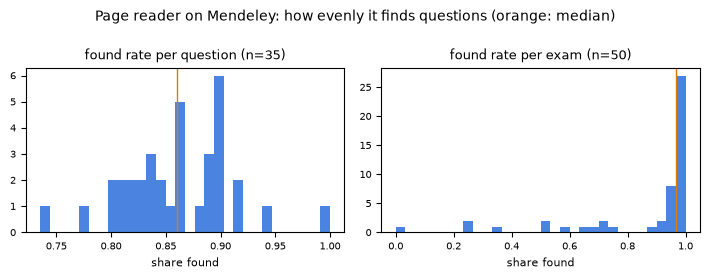

figure: found_rates.png


In [7]:
page_rows = rows[(rows["mode"] == "page") & rows["answered"]]
eda.show(page_rows.groupby("type")["found"].mean(), "Page reader, share of answered questions found, by type:")
by_question = page_rows.groupby("q")["found"].mean()
by_exam = page_rows.groupby("exam")["found"].mean()
eda.show(by_question.sort_values().head(5), "The five questions found least often:")
eda.histograms({"found rate per question": by_question, "found rate per exam": by_exam}, "share found",
               OUT / "found_rates.png", "Page reader on Mendeley: how evenly it finds questions (orange: median)")

In [8]:
mcq = rows[(rows["type"] == "mcq") & rows["read"].notna()]
confidence = mcq.groupby(["mode", "letter_right"])["ocr_conf"].describe()[["count", "mean", "50%"]]
eda.show(confidence, "Confidence of the letters read, right against wrong:")


Confidence of the letters read, right against wrong:


count   mean    50%
mode      letter_right                     
detectors False           4.0  0.199  0.128
          True            5.0  0.391  0.444
ocr       False          24.0  0.231  0.218
          True          117.0  0.424  0.366
page      False          14.0  0.928  0.999
          True          805.0  0.970  1.000
page-4b   False          16.0  0.876  0.981
          True          752.0  0.974  1.000
rules     False          15.0  0.286  0.233
          True           45.0  0.356  0.336

## Conclusion

**The product reader is Qwen3-VL-2B reading whole pages, chosen on public data and evaluated once on 50 real
exams: it finds 86% of the answered questions and reads multiple-choice letters with 99% accuracy when it reads
one.** The way there, step by step:

1. Trained detectors worked on their own data (step 1) but did not transfer to real exams (step 2).
2. The Mendeley exams became evaluation-only, and a development set of public handwriting was built (step 3).
3. On it, a vision-language model reading the whole page beat every line reader, with safeguards for loops and
   blank pages (step 4).
4. Fine-tuning it on exam-like pages (steps 5 and 6) lowered its loss but found fewer numbers on answer sheets,
   so it was not adopted.

**What the grading agent must know.** The reader's confidence barely separates right from wrong letters (median
about 1.00 for both), so it cannot decide review on its own. A question missing from the read, a question found
twice, or a number not in the key are the better review signals, and the agent uses them. Other limits: English
handwriting only (both the development set and the evaluation are in English), pages must be upright, printed
question text is read as part of the answer, and anything above the first question number (often the student's
name) goes to `unassigned` and must not be logged.